# Лабораторная работа 1. Линейная регрессия и факторный анализ  
**Выполнил:** Болтенков Евгений Олегович    
**Проверил:** Антонянц Егор Николаевич  
**Датасет:** QSAR Aquatic Toxicity (UCI Machine Learning Repository / Kaggle).  
**Задача:** по молекулярным дескрипторам химических соединений предсказать их острую токсичность для рыб — регрессия на непрерывной целевой переменной `LC50`.  
**План работы:** первичный анализ и визуализация → предобработка → корреляции и VIF → линейная, лассо- и гребневая регрессии с кросс-валидацией → стандартизация и PCA → те же модели на главных компонентах → сравнение метрик (RMSE, R², MAPE).   

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Загрузка и первичный анализ

In [2]:
DATA_PATH = "qsar_aquatic_toxicity.csv"   # файл лежит рядом с ноутбуком
COLUMNS = ["TPSA", "SAacc", "H050", "MLOGP", "RDCHI", "GATS1p", "nN", "C040", "LC50"]
# в файле нет строки заголовка (header=None), разделитель - точка с запятой (sep=";")
df_raw = pd.read_csv(DATA_PATH, sep=";", header=None, names=COLUMNS)

print("Размер исходной таблицы (строки, столбцы):", df_raw.shape)
print("\nТипы столбцов:")
print(df_raw.dtypes)
df_raw.head()

Размер исходной таблицы (строки, столбцы): (546, 9)

Типы столбцов:
TPSA      float64
SAacc     float64
H050        int64
MLOGP     float64
RDCHI     float64
GATS1p    float64
nN          int64
C040        int64
LC50      float64
dtype: object


,TPSA,SAacc,H050,MLOGP,RDCHI,GATS1p,nN,C040,LC50
0,0.0000,0.0000,0,2.4190,1.2250,0.6670,0,0,3.7400
1,0.0000,0.0000,0,2.6380,1.4010,0.6320,0,0,4.3300
2,9.2300,11.0000,0,5.7990,2.9300,0.4860,0,0,7.0190
3,9.2300,11.0000,0,5.4530,2.8870,0.4950,0,0,6.7230
4,9.2300,11.0000,0,4.0680,2.7580,0.6950,0,0,5.9790


## О датасете

Набор данных QSAR aquatic toxicity — это пример задачи **QSAR** (Quantitative Structure–Activity Relationship, «количественная связь структуры и активности»): по числовому описанию молекулы предсказывают её биологическое действие. Здесь рассматривается острая токсичность для пресноводной рыбы *Pimephales promelas* (толстоголовый гольян). Каждая строка — одно химическое соединение (**546 соединений**), столбцы — 8 рассчитанных молекулярных дескрипторов и измеренная токсичность.

**Целевая переменная — `LC50`**: концентрация вещества, при которой за 96 часов погибает 50% рыб; выражена как −log(моль/л), то есть **чем больше значение, тем токсичнее вещество** (для получения «обычной» концентрации нужно взять 10 в степени −LC50). Единицы измерения у LC50 логарифмические, поэтому RMSE ниже тоже измеряется в этих логарифмических единицах.

**Дескрипторы** (по описанию датасета на UCI; формулировки стоит сверить с первоисточником):

| Столбец | Что описывает | Тип |
|---|---|---|
| `TPSA` | топологическая полярная площадь поверхности молекулы | непрерывный |
| `SAacc` | площадь поверхности атомов — акцепторов водородной связи | непрерывный |
| `H050` | число атомов водорода, связанных с гетероатомами | целочисленный счётчик |
| `MLOGP` | расчётный коэффициент распределения октанол/вода (липофильность) | непрерывный |
| `RDCHI` | индекс связности молекулярного графа (размер и ветвление молекулы) | непрерывный |
| `GATS1p` | 2D-автокорреляция (Гири), отражает распределение поляризуемости атомов | непрерывный |
| `nN` | число атомов азота | целочисленный счётчик |
| `C040` | число фрагментов определённого типа (углерод, связанный с гетероатомами) | целочисленный счётчик |
| **`LC50`** | **токсичность, −log(моль/л)** | **цель, непрерывный** |

**Загрузка.** В файле нет строки заголовка и столбцы разделены точкой с запятой, поэтому `read_csv` вызван с `sep=";"` и `header=None`, а имена столбцов заданы вручную (`names=COLUMNS`). Без этих параметров pandas принял бы первую строку данных за заголовок и склеил бы все значения в один столбец. Результат: **546 строк × 9 столбцов**; `H050`, `nN`, `C040` — целые числа, остальные столбцы — вещественные; нечисловых столбцов нет. Первые строки показывают, что у многих простых соединений (например, углеводородов) `TPSA` и `SAacc` равны нулю — у них нет полярных атомов.

In [3]:
FEATURES = ["TPSA", "SAacc", "MLOGP", "RDCHI"]   # 4 количественных признака
TARGET = "LC50"                           # целевая переменная

df = df_raw[FEATURES + [TARGET]].copy()
print("Рабочая таблица:", df.shape)
df.info()

Рабочая таблица: (546, 5)
<class 'pandas.DataFrame'>
RangeIndex: 546 entries, 0 to 545
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   TPSA    546 non-null    float64
 1   SAacc   546 non-null    float64
 2   MLOGP   546 non-null    float64
 3   RDCHI   546 non-null    float64
 4   LC50    546 non-null    float64
dtypes: float64(5)
memory usage: 21.5 KB


**Выбор признаков и цели.** Для работы взяты 4 количественных непрерывных признака: `TPSA`, `SAacc`, `MLOGP`, `RDCHI`; цель — `LC50`. Остальные столбцы исключены:

- `H050`, `nN`, `C040` — целочисленные счётчики с большим количеством нулей (это скорее дискретные признаки, чем количественные);
- `GATS1p` — непрерывный, но ограничение «3–4 признака» требует выбрать только часть, и он слабее связан с целью и менее интересен для анализа коллинеарности.

Выбранный набор удобен ещё и тем, что в нём есть заметно взаимосвязанные признаки (`TPSA` и `SAacc`), поэтому проверка мультиколлинеарности и PCA имеют смысл. Матрицы `X` и `y` формируются позже, в ячейке разбиения выборки. `info()` показывает, что во всех пяти столбцах 546 непустых значений.

In [4]:
print("Пропуски по столбцам:")
print(df.isna().sum())
print("\nПолных дубликатов строк:", df.duplicated().sum())

Пропуски по столбцам:
TPSA     0
SAacc    0
MLOGP    0
RDCHI    0
LC50     0
dtype: int64

Полных дубликатов строк: 0


**Пропуски и дубликаты.** Пропусков нет ни в одном столбце, полных дубликатов строк тоже нет. Это упрощает работу, но ячейка удаления пропусков ниже всё равно выполняется, чтобы код соответствовал заданию и работал на «грязных» данных.

In [5]:
desc = df.describe().T
desc["skew"] = df.skew()
desc

,count,mean,std,min,25%,50%,75%,max,skew
TPSA,546.0000,48.4729,46.7640,0.0000,15.7900,40.4600,70.0225,347.3200,1.9188
SAacc,546.0000,58.8690,68.1666,0.0000,11.0000,42.6830,77.4928,571.9520,2.9897
MLOGP,546.0000,2.3135,1.7418,-6.4460,1.2325,2.2735,3.3927,9.1480,-0.2340
RDCHI,546.0000,2.4923,0.8110,1.0000,1.9750,2.3440,2.9110,6.4390,1.0300
LC50,546.0000,4.6584,1.6652,0.1220,3.6015,4.5160,5.6075,10.0470,0.3214


**Описательные статистики.** Главные особенности:

- `TPSA`: среднее 48.5 заметно больше медианы 40.5, максимум 347 — сильная правосторонняя асимметрия (1.92);
- `SAacc`: среднее 58.9, медиана 42.7, максимум 572 — самая сильная асимметрия (2.99) и самый широкий разброс;
- `MLOGP`: почти симметричен (асимметрия −0.23), среднее 2.31, диапазон от −6.4 до 9.1;
- `RDCHI`: диапазон 1–6.4, умеренная асимметрия вправо (1.03);
- `LC50`: среднее 4.66, медиана 4.52, диапазон 0.12–10.05, асимметрия небольшая (0.32).

Масштабы признаков различаются на порядки (`SAacc` до 572, `RDCHI` до 6.4), поэтому стандартизация обязательна.

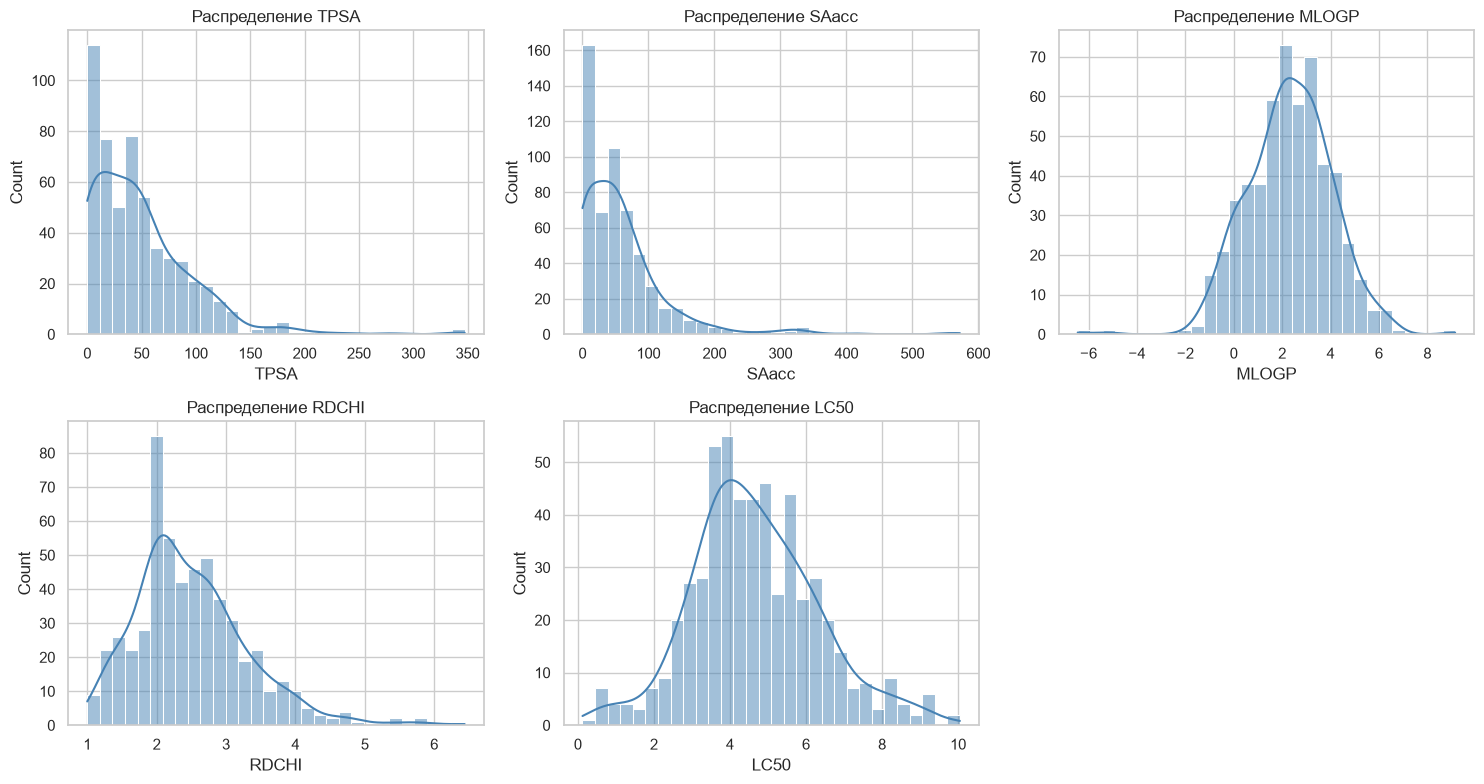

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), FEATURES + [TARGET]):
    sns.histplot(df[col], kde=True, bins=30, ax=ax, color="steelblue")
    ax.set_title(f"Распределение {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**Распределения признаков и целевой переменной.**

- **`TPSA`** — резкий пик в нуле (около 115 соединений в первой корзине) и длинный правый хвост до 347. Нулевые значения — это соединения без полярных атомов (17.8% выборки).
- **`SAacc`** — ещё более резкий пик в нуле (19.8% нулей) и очень длинный хвост, единичные значения до 570. Форма распределения очень похожа на `TPSA`, что предвещает сильную корреляцию этих признаков.
- **`MLOGP`** — почти колоколообразное распределение с центром около 2.3; единичные соединения с очень низкой (−6) и высокой (9) липофильностью.
- **`RDCHI`** — одновершинное распределение с максимумом около 2 и хвостом вправо до 6.4.
- **`LC50`** — приблизительно нормальное, с лёгким правым хвостом (высокотоксичные вещества) и небольшим левым плечом около 0–1.

Для линейной регрессии благоприятно, что целевая переменная близка к нормальной; скошенные `TPSA` и `SAacc` можно было бы логарифмировать, но в этой работе они остаются в исходной шкале.

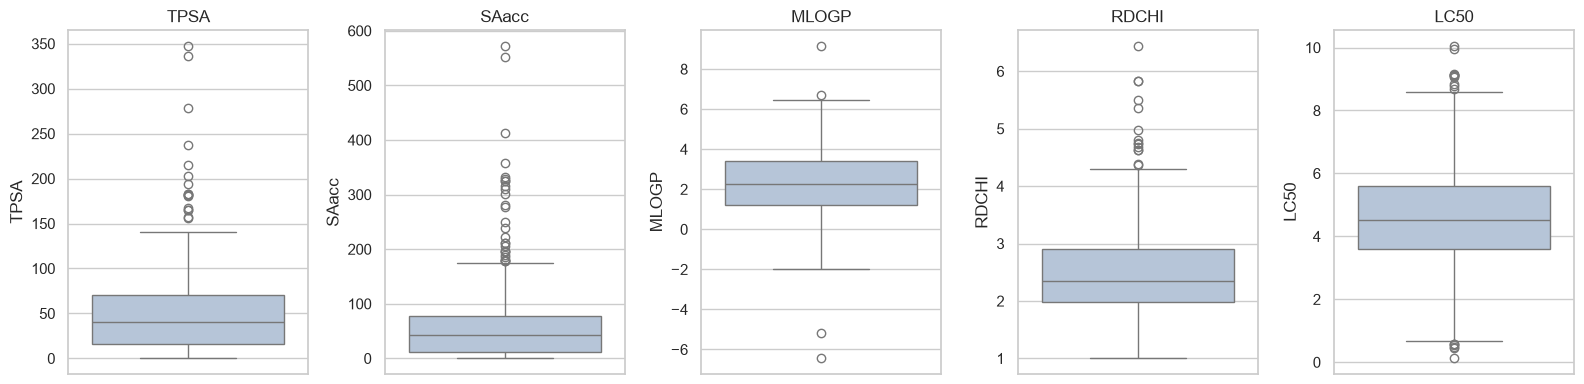

Доля нулевых значений TPSA, %: 17.8
Доля нулевых значений SAacc, %: 19.8


,выбросов по IQR,"доля, %"
TPSA,17,3.1136
SAacc,28,5.1282
MLOGP,4,0.7326
RDCHI,14,2.5641
LC50,17,3.1136


In [7]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, FEATURES + [TARGET]):
    sns.boxplot(y=df[col], ax=ax, color="lightsteelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

out_table = pd.DataFrame({"выбросов по IQR": {c: iqr_outliers(df[c].dropna()) for c in df.columns}})
out_table["доля, %"] = out_table["выбросов по IQR"] / len(df) * 100
print("Доля нулевых значений TPSA, %:", round((df["TPSA"] == 0).mean() * 100, 1))
print("Доля нулевых значений SAacc, %:", round((df["SAacc"] == 0).mean() * 100, 1))
out_table

**Выбросы.** Диаграммы размаха и подсчёт по правилу 1.5·IQR:

- **`TPSA`** — медиана около 40, «ящик» 16–70; 17 выбросов (3.1%), все выше ≈140, до 347.
- **`SAacc`** — медиана около 43, «ящик» 11–77; 28 выбросов (5.1%) выше ≈175, до 572. Больше всего выбросов среди признаков.
- **`MLOGP`** — симметричный «ящик», всего 4 выброса (0.7%): два на нижнем конце (около −5 и −6) и два на верхнем (около 6.7 и 9.1).
- **`RDCHI`** — 14 выбросов (2.6%), все выше ≈4.3, до 6.4.
- **`LC50`** — 17 выбросов (3.1%) в обе стороны: очень нетоксичные (≈0.1–0.6) и очень токсичные (выше ≈8.6, до 10).

**Решение: выбросы не удаляем.** Это не ошибки измерения, а реальные соединения (крупные полярные молекулы, сильные токсиканты). Их удаление сузило бы область, где модель применима, и исказило бы оценку качества. Влияние экстремальных значений ограничивают стандартизация и регуляризация (Lasso, Ridge).

## 2. Предобработка

In [8]:
n_before = len(df)
df_clean = df.dropna().reset_index(drop=True)
print(f"Было наблюдений: {n_before}, стало: {len(df_clean)}, удалено: {n_before - len(df_clean)}")
print("Пропусков осталось:", int(df_clean.isna().sum().sum()))

# категориальных признаков среди выбранных нет
print("Нечисловые столбцы:", df_clean.select_dtypes(exclude="number").columns.tolist())

Было наблюдений: 546, стало: 546, удалено: 0
Пропусков осталось: 0
Нечисловые столбцы: []


**Удаление пропусков.** Удалено 0 строк, осталось **546** наблюдений — пропусков не было. Категориальных (нечисловых) признаков среди выбранных нет, поэтому кодирование не требуется (ни One-Hot, ни порядковое).

## 3. Корреляции и мультиколлинеарность

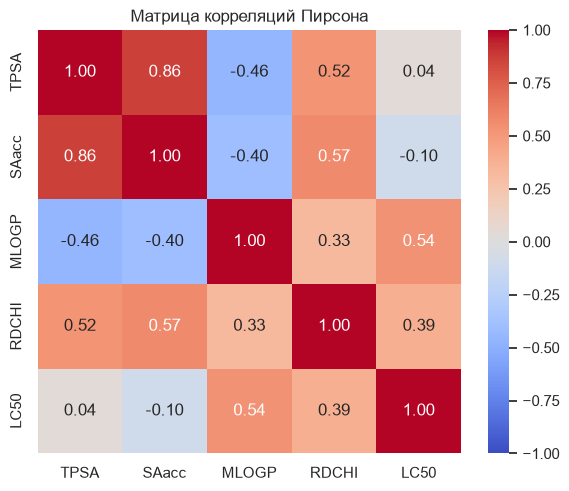

Корреляция признаков с целевой переменной (Пирсон / Спирмен):


,Pearson,Spearman
TPSA,0.0380,0.0169
SAacc,-0.0980,-0.1159
MLOGP,0.5355,0.5689
RDCHI,0.3906,0.4237


In [9]:
corr = df_clean.corr(method="pearson")

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Матрица корреляций Пирсона")
plt.show()

print("Корреляция признаков с целевой переменной (Пирсон / Спирмен):")
pd.DataFrame({
    "Pearson": corr[TARGET].drop(TARGET),
    "Spearman": df_clean.corr(method="spearman")[TARGET].drop(TARGET),
})

**Матрица корреляций (Пирсон).** Метод Пирсона выбран, потому что все переменные количественные, а линейная регрессия моделирует именно линейную связь. Корреляция Спирмена добавлена для проверки монотонных связей.

На тепловой карте (красный — положительная связь, синий — отрицательная):

- **`TPSA` и `SAacc`: 0.86** — самая сильная связь в наборе; обе величины измеряют площадь полярной поверхности, и это основной источник мультиколлинеарности.
- `RDCHI` умеренно связан с `SAacc` (0.57) и `TPSA` (0.52): более крупные и разветвлённые молекулы имеют больше полярных атомов.
- `MLOGP` связан с полярными признаками отрицательно (−0.46 с `TPSA`, −0.40 с `SAacc`): более полярные вещества хуже растворяются в жирах.
- **С целевой переменной**: `MLOGP` 0.54 и `RDCHI` 0.39 — заметные положительные связи; `TPSA` (0.04) и `SAacc` (−0.10) почти не коррелируют с `LC50` по отдельности. Таблица Спирмена даёт те же выводы (0.57, 0.42, 0.02, −0.12), то есть связи близки к линейным.

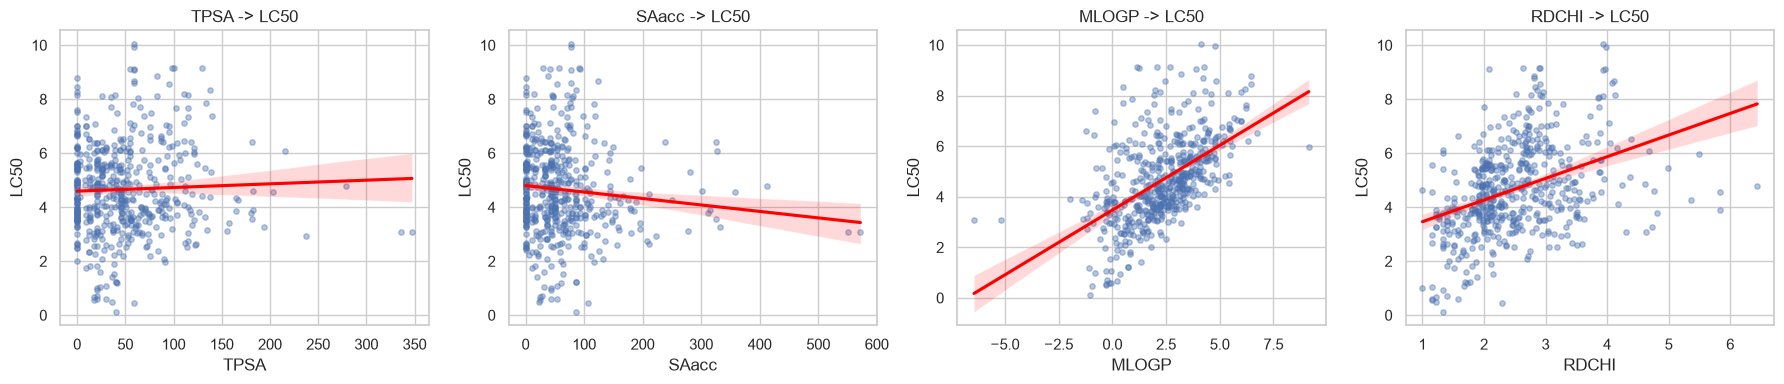

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, FEATURES):
    sns.regplot(x=df_clean[col], y=df_clean[TARGET], ax=ax,
                scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "red"})
    ax.set_title(f"{col} -> {TARGET}")
plt.tight_layout()
plt.show()

**Зависимость `LC50` от каждого признака** (красная линия — линейный тренд, полоса — доверительный интервал).

- **`TPSA` → `LC50`**: облако точек практически горизонтально, тренд почти плоский. Один этот признак токсичность не объясняет.
- **`SAacc` → `LC50`**: очень слабый отрицательный наклон; точки сильно рассеяны, а основная масса сгруппирована у нуля.
- **`MLOGP` → `LC50`**: чёткий положительный тренд — более липофильные вещества токсичнее для рыб (они лучше проникают через мембраны жабр). Это самый информативный признак, хотя разброс вокруг линии ощутим (особенно при MLOGP 0–5).
- **`RDCHI` → `LC50`**: умеренный положительный тренд с большим разбросом; наиболее токсичные соединения встречаются при RDCHI 2–4.

Вывод: линейная зависимость просматривается в основном у `MLOGP` и `RDCHI`, поэтому высокого R² ждать не стоит. Для `TPSA` и `SAacc` полезность может проявиться только совместно с другими признаками.

In [11]:
def compute_vif(X):
    """VIF_j = 1 / (1 - R^2_j), где R^2_j - от регрессии признака j на остальные признаки."""
    result = {}
    for col in X.columns:
        others = X.drop(columns=col)
        r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
        result[col] = 1 / (1 - r2)
    return pd.Series(result, name="VIF")

vif_original = compute_vif(df_clean[FEATURES])
vif_original.to_frame()

,VIF
TPSA,4.7977
SAacc,4.7759
MLOGP,3.3154
RDCHI,3.9159


**VIF.** Для каждого признака VIF = 1/(1−R²), где R² получен регрессией этого признака на остальные (функция написана вручную через `LinearRegression`, чтобы не зависеть от `statsmodels`). На вход подаются только признаки, без целевой переменной.

Результат: `TPSA` — **4.80**, `SAacc` — **4.78**, `RDCHI` — 3.92, `MLOGP` — 3.32. По общепринятым порогам (5 — осторожность, 10 — серьёзная проблема) мультиколлинеарность **умеренная, на границе допустимого**: `TPSA` и `SAacc` почти достигают порога 5, что согласуется с корреляцией 0.86. Из-за этого коэффициенты при них будут неустойчивыми и, как мы увидим, с противоположными знаками.

Что можно предложить: удалить один из пары `TPSA`/`SAacc` либо заменить их на главные компоненты — именно этим мы займёмся в разделе PCA. В основной части работы все четыре признака оставлены, чтобы затем честно сравнить исходные признаки и компоненты.

## 4. Разбиение выборки, метрики, модели на исходных признаках

In [12]:
X = df_clean[FEATURES]
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print(f"\nLC50: среднее train = {y_train.mean():.2f}, среднее test = {y_test.mean():.2f}")

X_train: (436, 4) | X_test: (110, 4)
y_train: (436,) | y_test: (110,)

LC50: среднее train = 4.69, среднее test = 4.52


**Разбиение 80/20.** Получено 436 обучающих и 110 тестовых наблюдений. `random_state=42` фиксирует перемешивание: при другом значении получатся другие тестовые соединения и другие метрики (разброс измерен в конце работы). Случайное разбиение допустимо: временной структуры нет, каждая строка — отдельное вещество; оговорка — в наборе могут быть структурно похожие молекулы, из-за чего оценка на тесте может быть немного оптимистичной. Среднее `LC50` в тесте (4.52) близко к обучающему (4.69), то есть выборки сопоставимы.

In [13]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))     # RMSE = sqrt(MSE), единицы - те же, что у LC50

def mape(y_true, y_pred):
    return mean_absolute_percentage_error(y_true, y_pred) * 100   # перевод доли в проценты

print("Минимум LC50:", y.min(), "| значений LC50 < 1:", int((y < 1).sum()), "| ровно 0:", int((y == 0).sum()))

Минимум LC50: 0.122 | значений LC50 < 1: 10 | ровно 0: 0


**Метрики.** RMSE = √MSE (единицы — те же, что у `LC50`, то есть логарифмические). R² — доля объяснённой дисперсии. MAPE переводится из доли в проценты умножением на 100.

**Важная оговорка про MAPE.** Нулевых значений `LC50` нет (минимум 0.122), но у 10 соединений `LC50 < 1`. MAPE делит ошибку на фактическое значение, поэтому на таких соединениях процентная ошибка огромна даже при небольшой абсолютной погрешности; кроме того, MAPE несимметрична. Поэтому MAPE здесь следует интерпретировать осторожно и ориентироваться в первую очередь на RMSE и R².

In [14]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alphas = np.logspace(-3, 2, 40)          # сетка параметра регуляризации: 0.001 ... 100

def fit_models(X_tr, y_tr, n_components=None):
    """Линейная, Lasso и Ridge. Все преобразования внутри Pipeline, поэтому в каждом
    разбиении кросс-валидации scaler (и PCA) заново обучаются только на обучающей части."""
    steps = [("scaler", StandardScaler())]
    if n_components is not None:
        steps.append(("pca", PCA(n_components=n_components)))

    models = {}
    lin = Pipeline(steps + [("model", LinearRegression())]).fit(X_tr, y_tr)
    models["Linear"] = lin

    for name, Est in [("Lasso", Lasso), ("Ridge", Ridge)]:
        gs = GridSearchCV(
            Pipeline(steps + [("model", Est(max_iter=10000))]),
            param_grid={"model__alpha": alphas},
            cv=cv, scoring="neg_root_mean_squared_error",
        )
        gs.fit(X_tr, y_tr)
        models[name] = gs
    return models

def summarize(models, X_tr, y_tr, X_te, y_te, label):
    rows = []
    for name, m in models.items():
        if isinstance(m, GridSearchCV):
            est, alpha, cv_rmse = m.best_estimator_, m.best_params_["model__alpha"], -m.best_score_
        else:
            est, alpha = m, np.nan
            cv_rmse = -cross_val_score(m, X_tr, y_tr, cv=cv, scoring="neg_root_mean_squared_error").mean()
        p_tr, p_te = est.predict(X_tr), est.predict(X_te)
        rows.append({
            "Признаки": label, "Модель": name, "alpha": alpha, "CV RMSE": cv_rmse,
            "Train RMSE": rmse(y_tr, p_tr), "Test RMSE": rmse(y_te, p_te),
            "Train R2": r2_score(y_tr, p_tr), "Test R2": r2_score(y_te, p_te),
            "Train MAPE, %": mape(y_tr, p_tr), "Test MAPE, %": mape(y_te, p_te),
        })
    return pd.DataFrame(rows)

models_orig = fit_models(X_train, y_train)
res_orig = summarize(models_orig, X_train, y_train, X_test, y_test, "Исходные")
res_orig

,Признаки,Модель,alpha,CV RMSE,Train RMSE,Test RMSE,Train R2,Test R2,"Train MAPE, %","Test MAPE, %"
0,Исходные,Linear,NaN,1.2562,1.2403,1.2027,0.4423,0.4797,27.0709,40.7486
1,Исходные,Lasso,0.0013,1.2562,1.2403,1.2031,0.4423,0.4793,27.0826,40.8708
2,Исходные,Ridge,2.8943,1.2557,1.2407,1.2030,0.4420,0.4794,27.1696,41.3686


**Модели на исходных признаках.** Все преобразования находятся внутри `Pipeline` (`StandardScaler → модель`), поэтому в каждом из 5 блоков кросс-валидации (`KFold`, перемешивание, метрика — отрицательный RMSE) стандартизатор заново обучается только на обучающей части блока, а тест нигде не участвует в подборе. Параметр `alpha` для Lasso и Ridge подбирается `GridSearchCV` по 40 значениям на логарифмической сетке от 0.001 до 100; `max_iter=10000` задан явно, остальные параметры — по умолчанию.

Результаты на тесте:

- линейная: RMSE 1.203, R² 0.480, MAPE 40.7%;
- лассо (α≈0.0013): RMSE 1.203, R² 0.479, MAPE 40.9%;
- гребневая (α≈2.9): RMSE 1.203, R² 0.479, MAPE 41.4%.

Три модели практически неразличимы: подобранный для Lasso α почти нулевой (регуляризация почти не нужна), а для Ridge эффект мал. Это объясняется тем, что признаков всего четыре, наблюдений много (436), а мультиколлинеарность умеренная. Модель объясняет около 48% дисперсии токсичности — для QSAR с четырьмя дескрипторами это ожидаемо.

Переобучения нет: R² на обучении (0.442) даже ниже, чем на тесте (0.480), а CV RMSE (1.256) близок к тестовому (1.203). Отставание теста по MAPE (27% на обучении против 41% на тесте) связано с MAPE: в тестовую часть попали соединения с малыми значениями `LC50`, на которых процентная ошибка велика.

In [15]:
coef_rows = {}
for name, m in models_orig.items():
    est = m.best_estimator_ if isinstance(m, GridSearchCV) else m
    coef_rows[name] = pd.Series(est.named_steps["model"].coef_, index=FEATURES)

coef_std = pd.DataFrame(coef_rows)       # коэффициенты при стандартизованных признаках
print("Коэффициенты (стандартизованные признаки):")
display(coef_std)

scale = models_orig["Linear"].named_steps["scaler"].scale_
print("Коэффициенты в исходных единицах (coef / std):")
display(coef_std.div(scale, axis=0))

Коэффициенты (стандартизованные признаки):


,Linear,Lasso,Ridge
TPSA,1.2596,1.2496,1.1939
SAacc,-0.9234,-0.9124,-0.8802
MLOGP,1.0234,1.0225,0.9984
RDCHI,0.1693,0.1670,0.1858


Коэффициенты в исходных единицах (coef / std):


,Linear,Lasso,Ridge
TPSA,0.0258,0.0256,0.0244
SAacc,-0.0127,-0.0125,-0.0121
MLOGP,0.5757,0.5752,0.5616
RDCHI,0.1997,0.1971,0.2191


**Коэффициенты моделей.** В первой таблице — коэффициенты при стандартизованных признаках (их можно сравнивать по величине), во второй — пересчитанные в исходные единицы.

- **`MLOGP`** (+1.02 на 1 стандартное отклонение, или +0.58 `LC50` на единицу MLOGP) — главный положительный фактор: липофильность повышает токсичность.
- **`TPSA` (+1.26) и `SAacc` (−0.92)** имеют большие коэффициенты **противоположных знаков**, хотя по отдельности с целью почти не связаны. Это типичный эффект коллинеарных признаков (подавление): модель использует не сами величины, а их разность. Отдельно интерпретировать эти коэффициенты нельзя — они неустойчивы.
- `RDCHI` (+0.17) вносит небольшой положительный вклад.
- Lasso почти не изменил коэффициенты (α≈0.001) и не обнулил ни одного признака. Ridge слегка сжал коэффициенты при коллинеарной паре (`TPSA` 1.26 → 1.19, `SAacc` −0.92 → −0.88).

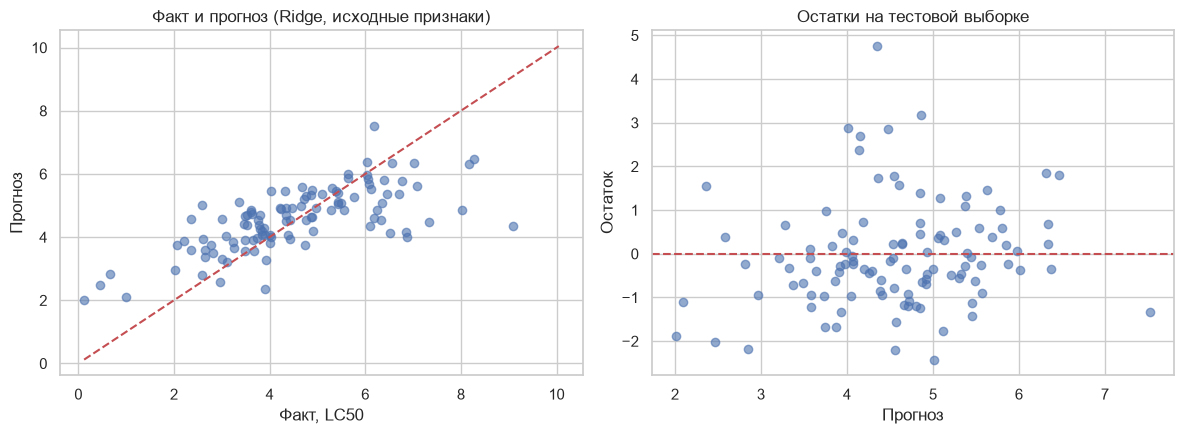

In [16]:
best_orig = res_orig.sort_values("CV RMSE").iloc[0]["Модель"]
m = models_orig[best_orig]
pred = m.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, pred, alpha=0.6)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
axes[0].set(xlabel="Факт, LC50", ylabel="Прогноз", title=f"Факт и прогноз ({best_orig}, исходные признаки)")
axes[1].scatter(pred, y_test - pred, alpha=0.6)
axes[1].axhline(0, color="r", ls="--")
axes[1].set(xlabel="Прогноз", ylabel="Остаток", title="Остатки на тестовой выборке")
plt.tight_layout()
plt.show()

**Прогноз и остатки** модели, лучшей по кросс-валидации на исходных признаках (гребневая регрессия).

- **Левый график (факт и прогноз).** Красная пунктирная линия — идеальное предсказание. Точки группируются вокруг неё в средней области (LC50 ≈ 3–6), но облако заметно «положе» диагонали: прогнозы лежат в узком диапазоне примерно 2–6.5, тогда как факт — от 0 до 10. Самые токсичные вещества (факт 8–9) модель занижает (прогноз 4–6.5), а самые малотоксичные (факт около 0–1) завышает (прогноз около 2–3). Это обычное для регрессии «сжатие к среднему» при слабой объясняющей способности признаков (R² ≈ 0.48).
- **Правый график (остатки).** Остатки разбросаны вокруг нуля без выраженного изгиба или «воронки», основная масса в пределах ±2; это говорит, что линейная форма модели в целом подходит и дисперсия ошибок примерно постоянна. Заметны отдельные большие положительные остатки (до +4.7): вещества, токсичнее предсказанного, — это те самые недооценённые высокотоксичные соединения.

## 5. PCA

     Доля дисперсии  Накопленная доля
PC1          0.6100            0.6100
PC2          0.3295            0.9395
PC3          0.0323            0.9719
PC4          0.0281            1.0000


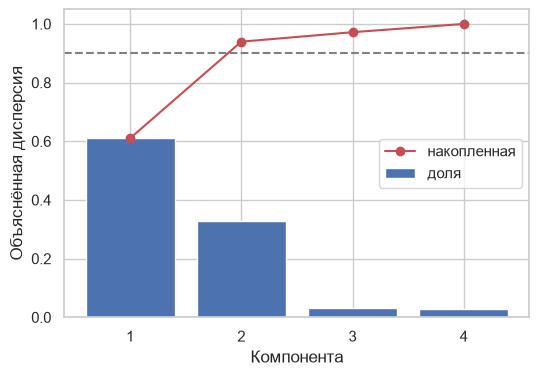

In [17]:
scaler_pca = StandardScaler().fit(X_train)            # fit - только на train
X_train_s = scaler_pca.transform(X_train)
X_test_s = scaler_pca.transform(X_test)               # test лишь преобразуется

pca_full = PCA().fit(X_train_s)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
print(pd.DataFrame({"Доля дисперсии": evr, "Накопленная доля": cum},
                   index=[f"PC{i+1}" for i in range(len(evr))]))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(range(1, len(evr) + 1), evr, label="доля")
ax.plot(range(1, len(evr) + 1), cum, "ro-", label="накопленная")
ax.axhline(0.90, color="gray", ls="--")
ax.set(xlabel="Компонента", ylabel="Объяснённая дисперсия", xticks=range(1, len(evr) + 1))
ax.legend()
plt.show()

**Стандартизация и PCA.** Стандартизатор обучается (`fit`) только на обучающей выборке, затем применяется (`transform`) к обучающей и тестовой выборкам — информация из теста не попадает в преобразование. PCA обучается на стандартизованных обучающих данных.

Доли объяснённой дисперсии: PC1 — 61.0%, PC2 — 33.0%, PC3 — 3.2%, PC4 — 2.8%. Накопленная доля (`np.cumsum`): 61.0% → **93.95%** → 97.2% → 100%.

**Как читать график.** Столбцы — доля дисперсии каждой компоненты, красная линия с точками — накопленная доля, серая пунктирная линия — порог 90%. Видно, что первые две компоненты вместе содержат почти всю дисперсию (≈94%), а PC3 и PC4 добавляют лишь по 3%. Резкий «излом» после второй компоненты показывает, что четыре признака фактически описывают двумерную структуру — это следствие сильной связи `TPSA`–`SAacc` и умеренных связей остальных пар.

Выбрано компонент: 2
Форма до PCA: (436, 4) -> после PCA: (436, 2) | тест: (110, 2)

Нагрузки (корреляции признаков с компонентами):


,PC1,PC2
TPSA,0.9568,-0.0922
SAacc,0.9611,-0.0124
MLOGP,-0.4222,0.8869
RDCHI,0.6544,0.7252


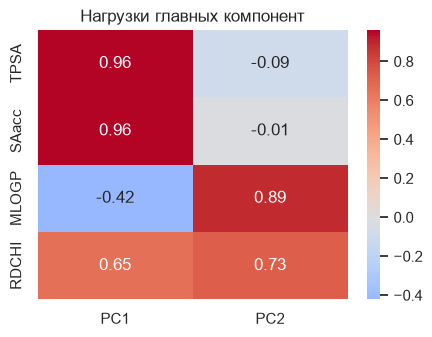

In [18]:
VAR_THRESHOLD = 0.90                                  # порог накопленной доли дисперсии
N_COMP = int(np.argmax(cum >= VAR_THRESHOLD) + 1)     # минимальное число компонент, достигающее порога
print("Выбрано компонент:", N_COMP)

pca = PCA(n_components=N_COMP).fit(X_train_s)
X_train_pc = pca.transform(X_train_s)
X_test_pc = pca.transform(X_test_s)                   # тест переводится теми же осями
print("Форма до PCA:", X_train_s.shape, "-> после PCA:", X_train_pc.shape, "| тест:", X_test_pc.shape)

pc_names = [f"PC{i+1}" for i in range(N_COMP)]
loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_),
                        index=FEATURES, columns=pc_names)
print("\nНагрузки (корреляции признаков с компонентами):")
display(loadings)

plt.figure(figsize=(5, 3.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Нагрузки главных компонент")
plt.show()

**Выбор числа компонент и нагрузки.** Число компонент выбрано по порогу накопленной дисперсии 90%: минимальное k, при котором накопленная доля ≥ 0.90, — **k = 2** (94%). Размер обучающей матрицы изменился с (436, 4) на (436, 2); тестовая выборка преобразуется теми же осями (`pca.transform`) и имеет форму (110, 2).

**Нагрузки** (таблица и тепловая карта; значения — корреляции исходного признака с компонентой, красный — положительная, синий — отрицательная связь):

- **PC1** — `SAacc` (0.96) и `TPSA` (0.96) почти одинаково положительно, `RDCHI` (0.65) положительно, `MLOGP` (−0.42) отрицательно: это ось «полярности и размера молекулы» — полярные крупные молекулы имеют большие значения.
- **PC2** — `MLOGP` (0.89) и `RDCHI` (0.73) положительно, `TPSA` и `SAacc` около нуля: ось «липофильности и размера». Именно эта компонента связана с токсичностью (через `MLOGP`).

Таким образом, две сильно коррелирующие величины `TPSA` и `SAacc` свёрнуты в одну компоненту PC1.

In [19]:
pc_df = pd.DataFrame(X_train_pc, columns=pc_names)
print("Корреляции между компонентами (train):")
display(pc_df.corr())
print("VIF компонент:")
display(compute_vif(pc_df).to_frame())

Корреляции между компонентами (train):


,PC1,PC2
PC1,1.0000,0.0000
PC2,0.0000,1.0000


VIF компонент:


,VIF
PC1,1.0000
PC2,1.0000


**Проверка устранения мультиколлинеарности.** Матрица корреляций компонент — единичная (внедиагональные значения равны нулю с точностью до округления), VIF каждой компоненты равен 1.0. Мультиколлинеарность в формальном смысле устранена: по построению PCA компоненты ортогональны. Платой стало сокращение размерности (4 → 2 признака) и потеря части информации (6% дисперсии).

## 6. Модели на главных компонентах и сравнение

In [20]:
# основной вариант (N_COMP компонент) и контрольные: 4 компоненты (без сокращения) и 3 компоненты
pca_variants = sorted({len(FEATURES), 3, N_COMP, 2}, reverse=True)
models_pca, res_pca_list = {}, []
for k in pca_variants:
    models_pca[k] = fit_models(X_train, y_train, n_components=k)
    res_pca_list.append(summarize(models_pca[k], X_train, y_train, X_test, y_test, f"PCA ({k} комп.)"))

res_pca = res_pca_list[pca_variants.index(N_COMP)]
res_pca

,Признаки,Модель,alpha,CV RMSE,Train RMSE,Test RMSE,Train R2,Test R2,"Train MAPE, %","Test MAPE, %"
0,PCA (2 комп.),Linear,NaN,1.3852,1.3798,1.3072,0.3099,0.3853,30.4102,52.7571
1,PCA (2 комп.),Lasso,0.0010,1.3852,1.3798,1.3074,0.3099,0.3852,30.4151,52.7771
2,PCA (2 комп.),Ridge,7.0170,1.3851,1.3798,1.3095,0.3098,0.3832,30.4782,53.0482


**Модели на главных компонентах.** Те же три модели, та же сетка `alpha`, те же разбиения кросс-валидации и тот же тест (те же 110 наблюдений, `random_state=42`) — условия сравнения одинаковы. Внутри `Pipeline` (`StandardScaler → PCA → модель`) PCA заново обучается на каждом блоке кросс-валидации. Основной вариант — k=2 (по порогу 90%); дополнительно рассчитаны k=4 (повёрнутые, но не сокращённые признаки) и k=3.

Для k=2 качество заметно хуже, чем на исходных признаках: CV RMSE 1.385 против 1.256, тест RMSE ≈ 1.31 против 1.20, R² 0.385 против 0.480, MAPE ≈ 53% против 41%. Подробное сравнение — в следующей таблице.

In [21]:
results = pd.concat([res_orig] + res_pca_list, ignore_index=True)
cols = ["Признаки", "Модель", "alpha", "CV RMSE", "Test RMSE", "Test R2", "Test MAPE, %"]
display(results[cols])

# изменение при переходе от исходных признаков к главным компонентам (всем вариантам PCA)
base = res_orig.set_index("Модель")
delta_rows = []
for r in res_pca_list:
    r = r.set_index("Модель")
    d = pd.DataFrame({
        "dRMSE": r["Test RMSE"] - base["Test RMSE"],
        "dR2": r["Test R2"] - base["Test R2"],
        "dMAPE, п.п.": r["Test MAPE, %"] - base["Test MAPE, %"],
    })
    d.insert(0, "Признаки", r["Признаки"])
    delta_rows.append(d.reset_index())
print("Изменение метрик на тесте (PCA минус исходные признаки):")
pd.concat(delta_rows, ignore_index=True)

,Признаки,Модель,alpha,CV RMSE,Test RMSE,Test R2,"Test MAPE, %"
0,Исходные,Linear,NaN,1.2562,1.2027,0.4797,40.7486
1,Исходные,Lasso,0.0013,1.2562,1.2031,0.4793,40.8708
2,Исходные,Ridge,2.8943,1.2557,1.2030,0.4794,41.3686
3,PCA (4 комп.),Linear,NaN,1.2562,1.2027,0.4797,40.7486
4,PCA (4 комп.),Lasso,0.0010,1.2563,1.2026,0.4797,40.8316
5,PCA (4 комп.),Ridge,2.8943,1.2557,1.2030,0.4794,41.3686
6,PCA (3 комп.),Linear,NaN,1.2675,1.1975,0.4841,42.0125
7,PCA (3 комп.),Lasso,0.0010,1.2676,1.1978,0.4839,42.0779
8,PCA (3 комп.),Ridge,1.6037,1.2673,1.1983,0.4835,42.3252
9,PCA (2 комп.),Linear,NaN,1.3852,1.3072,0.3853,52.7571


Изменение метрик на тесте (PCA минус исходные признаки):


,Модель,Признаки,dRMSE,dR2,"dMAPE, п.п."
0,Linear,PCA (4 комп.),0.0000,-0.0000,0.0000
1,Lasso,PCA (4 комп.),-0.0004,0.0004,-0.0392
2,Ridge,PCA (4 комп.),0.0000,0.0000,0.0000
3,Linear,PCA (3 комп.),-0.0052,0.0045,1.2640
4,Lasso,PCA (3 комп.),-0.0053,0.0046,1.2070
5,Ridge,PCA (3 комп.),-0.0047,0.0041,0.9566
6,Linear,PCA (2 комп.),0.1045,-0.0943,12.0085
7,Lasso,PCA (2 комп.),0.1043,-0.0942,11.9063
8,Ridge,PCA (2 комп.),0.1065,-0.0962,11.6796


**Итоговая таблица метрик (тест) и разности «PCA минус исходные признаки».**

- **k=4** (PCA без сокращения): результаты линейной и гребневой регрессий совпадают с исходными — это просто поворот осей, который для линейной модели ничего не меняет. У лассо отличия в четвёртом знаке: L1-штраф не инвариантен к повороту.
- **k=3**: тест RMSE на 0.005 ниже (1.198 против 1.203), R² на 0.004 выше, но MAPE на 1.0–1.3 п.п. хуже; CV RMSE хуже (1.268 против 1.256). Фактически качество не изменилось.
- **k=2** (выбранный по порогу 90%): **ухудшение по всем метрикам** — RMSE +0.10–0.11, R² −0.09…−0.10, MAPE +11.7–12.0 п.п.

То есть PCA улучшил результат только в пределах шума (k=3 по RMSE и R²) и ухудшил результат при выбранном по порогу k=2. Объяснение: в 6% дисперсии, отброшенных при k=2, содержится информация, существенная для прогноза — вероятно, различие между `TPSA` и `SAacc` (напомним, что их коэффициенты в обычной регрессии имели противоположные знаки); при k=3 эту информацию возвращает третья компонента, и качество восстанавливается. Это предположение, но оно согласуется с тем, что добавление компоненты PC3 вернуло качество к исходному уровню. Критерий «90% дисперсии» оказался неудачным: высокая доля дисперсии признаков не гарантирует, что сохранена информация о целевой переменной.

           mean    std    min    max
Признаки                            
PCA (2)  1.3910 0.0814 1.2166 1.5273
PCA (3)  1.2735 0.0790 1.0875 1.4187
Исходные 1.2617 0.0803 1.0899 1.3955


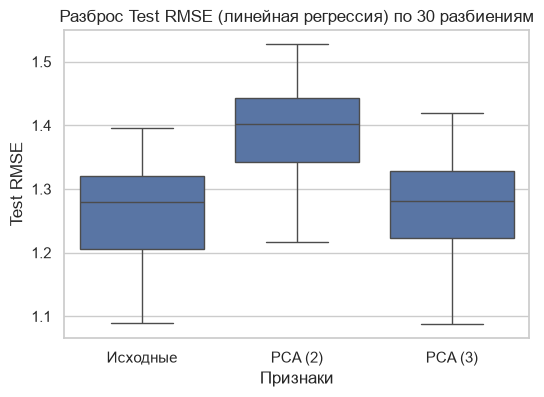

In [22]:
rows = []
for seed in range(30):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed)
    for label, steps in [("Исходные", [StandardScaler()]),
                         (f"PCA ({N_COMP})", [StandardScaler(), PCA(n_components=N_COMP)]),
                         ("PCA (3)", [StandardScaler(), PCA(n_components=3)])]:
        p = Pipeline([(f"s{i}", s) for i, s in enumerate(steps)] + [("m", LinearRegression())])
        p.fit(Xtr, ytr)
        rows.append({"seed": seed, "Признаки": label, "Test RMSE": rmse(yte, p.predict(Xte))})
seed_df = pd.DataFrame(rows)
print(seed_df.groupby("Признаки")["Test RMSE"].agg(["mean", "std", "min", "max"]))

plt.figure(figsize=(6, 4))
sns.boxplot(data=seed_df, x="Признаки", y="Test RMSE")
plt.title("Разброс Test RMSE (линейная регрессия) по 30 разбиениям")
plt.show()

**Устойчивость выводов к разбиению.** На графике — распределение тестового RMSE линейной регрессии по 30 различным `random_state` (линия внутри «ящика» — медиана, «ящик» — межквартильный размах, «усы» — разброс без выбросов) для трёх вариантов: исходные признаки, PCA(3) и PCA(2).

- **Исходные признаки и PCA(3)** практически совпадают: средний RMSE 1.262 и 1.274, «ящики» перекрываются почти полностью. Разница в 0.012 в десять раз меньше стандартного отклонения между разбиениями (≈0.08).
- **PCA(2)** сдвинут вверх: средний RMSE 1.391, медиана около 1.40 против 1.28 у остальных. Ухудшение при k=2 воспроизводится на разных разбиениях, то есть не случайно.

Значит, вывод устойчив: на этих данных PCA с сокращением до 2 компонент ухудшает качество, а с 3 компонентами — не даёт заметной разницы.

## Выводы

1. **Данные.** 546 соединений, 4 выбранных признака (`TPSA`, `SAacc`, `MLOGP`, `RDCHI`) и цель `LC50`; пропусков и дубликатов нет. `TPSA` и `SAacc` сильно скошены вправо и содержат много нулей (соединения без полярных атомов), `MLOGP` и `LC50` близки к нормальным. Выбросы (до 5% по признакам) оставлены как реальные наблюдения.
2. **Связь с целью.** Токсичность растёт с липофильностью (`MLOGP`, r = 0.54) и размером молекулы (`RDCHI`, r = 0.39); `TPSA` и `SAacc` по отдельности почти не связаны с `LC50`.
3. **Мультиколлинеарность.** Корреляция `TPSA`–`SAacc` = 0.86, VIF ≈ 4.8 у обоих — умеренная проблема, на границе порога 5. Она проявляется в коэффициентах противоположных знаков при этих признаках.
4. **Модели на исходных признаках.** Линейная, лассо- и гребневая регрессии дают практически одинаковый результат: тестовый RMSE ≈ 1.20 (в логарифмических единицах `LC50`), R² ≈ 0.48, MAPE ≈ 41%. Лучшая по кросс-валидации — гребневая (α≈2.9), но выигрыш ничтожен. Переобучения нет. Если логарифм десятичный, RMSE 1.2 означает, что типичная ошибка прогноза концентрации составляет около одного порядка и более.
5. **PCA.** Две первые компоненты объясняют 94% дисперсии и полностью устраняют корреляции (VIF = 1), но качество падает (R² 0.38 против 0.48, RMSE +0.10, MAPE +12 п.п.). При k=3 качество совпадает с исходным, при k=4 — идентично (поворот осей). Эти выводы подтверждены 30 разными разбиениями.
6. **Итог сравнения.** PCA не улучшил ни одну из моделей: при k=2 он ухудшил все три, при k=3 различия в пределах шума. Умеренная мультиколлинеарность не мешает линейной регрессии на 436 наблюдениях, а Ridge справляется с ней сам. PCA оправдан, если нужно сократить размерность без потери качества (k=3) или если требуется ортогональность признаков.
7. **Причины ошибки и возможные улучшения.** Модель объясняет менее половины дисперсии: выбраны всего 4 из 8 дескрипторов (остальные, включая `GATS1p` и `nN`, не использованы), связи могут быть нелинейными, а `TPSA` и `SAacc` сильно скошены (возможно логарифмирование). Эти идеи в работе не реализованы и требуют отдельной проверки; сравнение моделей по MAPE следует делать с осторожностью из-за малых значений `LC50`.